# AI Delivery Time Prediction: Pickup to Arrival
**AI Application:** Regression (delivery time prediction)  
**Algorithm/Approach:** Linear Regression (base model), with Ridge and Lasso regularisation  

Dataset: `Train.csv` (21,201 motorbike delivery orders, Nairobi). Target: time from pickup to arrival at destination.


In [ ]:
import pandas as pd, numpy as np, warnings, matplotlib.pyplot as plt, scipy.stats as st
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split, KFold, GroupKFold, cross_val_score
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
plt.rcParams.update({"figure.dpi":90,"axes.spines.top":False,"axes.spines.right":False})
RS = 42

## 1. Data cleaning

### 1.1 Initial Shape

In [ ]:
df = pd.read_csv("Train.csv")
print(df.shape)
display(df.dtypes.to_frame("dtype").T)
miss = df.isna().sum(); display(miss[miss>0].to_frame("missing").assign(pct=lambda d:(d.missing/len(df)*100).round(1)))
print("Duplicate orders:", df["Order No"].duplicated().sum(), "| Constant columns:", [c for c in df if df[c].nunique()==1])

(21201, 29)


,Order No,User Id,Vehicle Type,Platform Type,Personal or Business,Placement - Day of Month,Placement - Weekday (Mo = 1),Placement - Time,Confirmation - Day of Month,Confirmation - Weekday (Mo = 1),...,Arrival at Destination - Time,Distance (KM),Temperature,Precipitation in millimeters,Pickup Lat,Pickup Long,Destination Lat,Destination Long,Rider Id,Time from Pickup to Arrival
dtype,object,object,object,int64,object,int64,int64,object,int64,int64,...,object,int64,float64,float64,float64,float64,float64,float64,object,int64


,missing,pct
Temperature,4366,20.6
Precipitation in millimeters,20649,97.4


Duplicate orders: 0 | Constant columns: ['Vehicle Type']


**Observations.** 21,201 orders × 29 columns, no duplicate orders. Two columns have missing values: `Temperature` (20.6%) and `Precipitation` (97.4%). `Vehicle Type` has one value (all bikes), so it carries no information and is dropped. `Order No` and `User Id` are identifiers, not predictors.

### 1.2 Parse timestamps, build the target and check for leakage

In [ ]:
def tsec(c): return (pd.to_datetime(df[c], format="%I:%M:%S %p") - pd.Timestamp("1900-01-01")).dt.total_seconds()
stages = ["Placement","Confirmation","Arrival at Pickup","Pickup","Arrival at Destination"]
for s in stages: df[s+"_s"] = tsec(s+" - Time")
leak = (df["Arrival at Destination_s"] - df["Pickup_s"]) == df["Time from Pickup to Arrival"]
print("Target equals (arrival time - pickup time) in", round(leak.mean()*100,2), "% of rows")
df["target_min"] = df["Time from Pickup to Arrival"]/60        # seconds -> minutes
# stage gaps that are known BEFORE the rider leaves with the parcel
df["conf_lag"]  = df["Confirmation_s"]-df["Placement_s"]
df["atp_lag"]   = df["Arrival at Pickup_s"]-df["Confirmation_s"]
df["pick_wait"] = df["Pickup_s"]-df["Arrival at Pickup_s"]
df["speed_kmh"] = df["Distance (KM)"]/(df["Time from Pickup to Arrival"]/3600)

Target equals (arrival time - pickup time) in 100.0 % of rows


**Finding: target leakage.** The target equals *arrival time − pickup time* in 100% of rows. The `Arrival at Destination` fields therefore contain the answer and **must not be used as inputs**; a model given them would score near-perfectly and be useless in practice. Because the goal is to predict at pickup, the only time information kept is what is known by then: how long confirmation took (`conf_lag`), how long the rider took to reach the pickup point (`atp_lag`), and how long the rider waited at pickup (`pick_wait`). The target was converted from seconds to minutes.

### 1.3 Detect invalid records

Cross-day records                     2
Timestamps out of order               6
Implausible speed or under 60 s    1089
Any of the above                   1096
dtype: int64


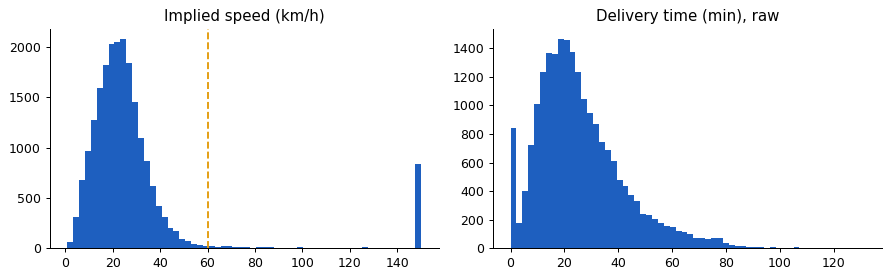

In [ ]:
day_cols = [s+" - Day of Month" for s in stages]
m_day   = df[day_cols].nunique(axis=1) > 1                    # stages spanning different days
m_order = df["conf_lag"] < 0                                   # confirmed before the order was placed
m_speed = (df["speed_kmh"] > 60) | (df["Time from Pickup to Arrival"] < 60)  # impossible for a motorbike in traffic
print(pd.Series({"Cross-day records":m_day.sum(),"Timestamps out of order":m_order.sum(),
                 "Implausible speed or under 60 s":m_speed.sum(),"Any of the above":(m_day|m_order|m_speed).sum()}))
fig,ax = plt.subplots(1,2,figsize=(10,3.2))
ax[0].hist(df["speed_kmh"].clip(upper=150),bins=60,color="#1E5FBF"); ax[0].axvline(60,color="#E39B0B",ls="--"); ax[0].set_title("Implied speed (km/h)")
ax[1].hist(df["target_min"].clip(upper=140),bins=60,color="#1E5FBF"); ax[1].set_title("Delivery time (min), raw"); plt.tight_layout(); plt.show()

**Finding.** 1,096 records (5.2%) are invalid: 2 span different days, 6 have a confirmation time before the order was placed, and 1,089 imply a speed above 60 km/h or a trip under 60 seconds. The histogram shows a spike of near-zero delivery times and implied speeds far beyond what a motorbike can do in traffic. The most likely cause is riders tapping "arrived" without travelling (a recording error, not a real delivery). These rows were removed because they would teach the model that long trips can take seconds. The 60 km/h cut-off is a judgement call; the median implied speed of the remaining data is about 22 km/h.

### 1.4 Missing values

In [ ]:
df["rain"] = df["Precipitation in millimeters"].notna().astype(int)      # blank = no rain recorded
df["Precipitation in millimeters"] = df["Precipitation in millimeters"].fillna(0)
df["temp_missing"] = df["Temperature"].isna().astype(int)
print("Rain recorded in", df["rain"].mean().round(3)*100, "% of orders; temperature missing in", df["temp_missing"].mean().round(3)*100, "%")

Rain recorded in 2.6 % of orders; temperature missing in 20.599999999999998 %


**Decision.** A blank precipitation value is treated as "no rain recorded", because only 2.6% of orders have a value and the readings that exist are positive. Temperature (20.6% missing) is filled with the median and a missing-indicator is kept. This is a simplification: the data does not say *why* values are missing. Therefore weather effects must be read with caution.

### 1.5 Remove invalid rows, drop unusable columns, engineer features

In [ ]:
clean = df[~(m_day|m_order|m_speed)].copy()
# temperature imputed with the median (fitted on the full cleaned set; the effect is negligible, see note)
clean["Temperature"] = clean["Temperature"].fillna(clean["Temperature"].median())
clean["hour"] = (clean["Pickup_s"]//3600).astype(int)
clean["weekday"] = clean["Placement - Weekday (Mo = 1)"]
clean["day"] = clean["Placement - Day of Month"]
clean["hour_sin"] = np.sin(2*np.pi*clean["hour"]/24); clean["hour_cos"] = np.cos(2*np.pi*clean["hour"]/24)
clean["business"] = (clean["Personal or Business"]=="Business").astype(int)
R=6371; a,b,c,d = map(np.radians,[clean["Pickup Lat"],clean["Pickup Long"],clean["Destination Lat"],clean["Destination Long"]])
clean["straight_km"] = 2*R*np.arcsin(np.sqrt(np.sin((c-a)/2)**2+np.cos(a)*np.cos(c)*np.sin((d-b)/2)**2))
clean = clean.rename(columns={"Distance (KM)":"distance_km","Temperature":"temp","Precipitation in millimeters":"precip_mm",
   "Pickup Lat":"p_lat","Pickup Long":"p_lon","Destination Lat":"d_lat","Destination Long":"d_lon","Platform Type":"platform"})
FEATURES = ["distance_km","straight_km","hour_sin","hour_cos","weekday","day","temp","precip_mm","rain","business",
            "p_lat","p_lon","d_lat","d_lon","atp_lag","pick_wait","conf_lag"]
X = pd.concat([clean[FEATURES], pd.get_dummies(clean["platform"],prefix="platform",drop_first=True).astype(int)],axis=1)
y = clean["target_min"]; groups = clean["Rider Id"]
print(f"Rows: {len(df):,} -> {len(clean):,}  ({len(df)-len(clean):,} removed, {(1-len(clean)/len(df))*100:.1f}%)   Features: {X.shape[1]}")
print("Dropped: Vehicle Type (constant), Order No / User Id (identifiers), Arrival at Destination fields (leak the target), duplicate day/weekday columns, Rider Id (kept only for grouped validation)")

Rows: 21,201 -> 20,105  (1,096 removed, 5.2%)   Features: 20
Dropped: Vehicle Type (constant), Order No / User Id (identifiers), Arrival at Destination fields (leak the target), duplicate day/weekday columns, Rider Id (kept only for grouped validation)


**Notes and limits of the cleaning.**
- Rider Id has 924 values, too many for one-hot encoding, so it is **not** a model feature. It is used only for grouped validation in section 4.1.
- The temperature median was computed on the full cleaned set before splitting. The effect is negligible for a single median value, but a stricter pipeline would fit it on the training set only.
- Models are scored against *cleaned* labels, so reported error applies to valid deliveries only, not to orders with bad records.
- The dataset has day of month and weekday but no month or year, so a time-ordered train/test split is not possible; a random split is used.

### 1.6 Cleaning summary
| Step | Rows | Decision |
|---|---|---|
| Raw | 21,201 | |
| Cross-day records | −2 | Delivery spanning midnight cannot be timed with these fields |
| Timestamps out of order | −6 | Recording errors |
| Speed above 60 km/h or time under 60 s | −1,089 | Physically implausible for a motorbike; likely rider tapped "arrived" without travelling |
| **Modelling set** | **20,105** | 5.2% removed |

## 2. Exploratory data analysis

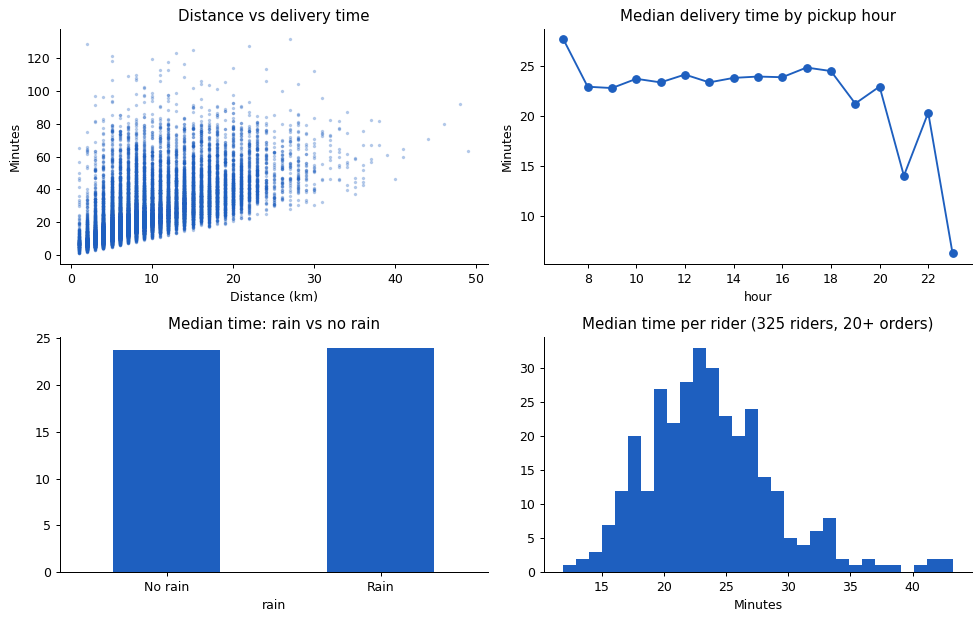

             count  median
distance_km               
(0, 3]        1929    10.1
(3, 6]        5013    15.8
(6, 10]       6043    22.6
(10, 15]      4028    29.8
(15, 50]      3092    40.5
Correlation distance vs time: 0.599 | skew of target: 1.37
Weekday medians: {1: 22.9, 2: 24.0, 3: 24.1, 4: 23.6, 5: 24.2, 6: 21.8, 7: 26.4}
Spread of rider medians (min): {'min': 11.9, '25%': 20.1, '50%': 23.2, '75%': 26.6, 'max': 43.2}
Correlation of pre-pickup gaps with time: {'atp_lag': 0.162, 'pick_wait': 0.03, 'conf_lag': 0.032}


In [ ]:
fig,ax = plt.subplots(2,2,figsize=(11,7))
ax[0,0].scatter(clean["distance_km"],y,s=3,alpha=.25,color="#1E5FBF"); ax[0,0].set_xlabel("Distance (km)"); ax[0,0].set_ylabel("Minutes"); ax[0,0].set_title("Distance vs delivery time")
clean.groupby("hour")["target_min"].median().plot(ax=ax[0,1],marker="o",color="#1E5FBF"); ax[0,1].set_title("Median delivery time by pickup hour"); ax[0,1].set_ylabel("Minutes")
clean.groupby("rain")["target_min"].median().rename({0:"No rain",1:"Rain"}).plot.bar(ax=ax[1,0],color="#1E5FBF",rot=0); ax[1,0].set_title("Median time: rain vs no rain")
r = clean.groupby("Rider Id")["target_min"].agg(["count","median"]); r = r[r["count"]>=20]
ax[1,1].hist(r["median"],bins=30,color="#1E5FBF"); ax[1,1].set_title(f"Median time per rider ({len(r)} riders, 20+ orders)"); ax[1,1].set_xlabel("Minutes")
plt.tight_layout(); plt.show()
print(clean.groupby(pd.cut(clean["distance_km"],[0,3,6,10,15,50]))["target_min"].agg(["count","median"]).round(1))
print("Correlation distance vs time:", clean[["distance_km","target_min"]].corr().iloc[0,1].round(3), "| skew of target:", y.skew().round(2))
print("Weekday medians:", clean.groupby("weekday")["target_min"].median().round(1).to_dict())
print("Spread of rider medians (min):", r["median"].describe().round(1)[["min","25%","50%","75%","max"]].to_dict())
print("Correlation of pre-pickup gaps with time:", clean[["atp_lag","pick_wait","conf_lag"]].corrwith(y).round(3).to_dict())

**EDA observations**
1. **Distance is by far the strongest driver.** Median delivery time rises from 10.1 min (≤3 km) to 15.8, 22.6, 29.8 and 40.5 min (>15 km), with a correlation of 0.60 between distance and time. Yet the scatter is wide at every distance, so distance alone cannot give an accurate estimate.
2. **The target is right-skewed (skew 1.37).** Most deliveries take 15–40 minutes but a long tail runs to over two hours. Errors will be larger on the slow deliveries, and the mean is pulled above the median (27.2 vs 23.7 min).
3. **Time of day, weekday and rain barely move the median.** Hourly medians sit in a narrow band around 23 min through the main trading hours, weekday medians run 21.8–24.2 min, and rain gives 23.9 vs 23.7 min. Rain was recorded for only 2.6% of orders, so this is weak evidence.
4. **Riders differ meaningfully.** Across 325 riders with 20+ orders, median delivery time ranges from 11.9 to 43.2 min. Part of this is route and distance mix, but it suggests rider-level behaviour matters and is not captured by the available features.
5. **Pre-pickup gaps are weak signals.** The time a rider took to reach pickup (`atp_lag`) correlates 0.16 with delivery time; waiting at pickup and confirmation delay correlate about 0.03.
6. **Data quality.** 5.2% of records were invalid, which shows that rider-entered timestamps cannot be fully trusted.

## 3. Base model: Linear Regression with regularisation

**Approach.** Multiple linear regression estimated by OLS is the base model, with Ridge (L2) and Lasso (L1) regularisation added as the guideline asks for regression tasks. Features are standardised so penalties act evenly. The regularisation strength (alpha) is chosen by cross-validation on the training set only. Delivery time is measured in minutes.
**Validity measures applied:** (1) held-out 20% test set never touched during fitting or tuning;
(2) 5-fold cross-validation;
(3) regularisation compared against plain OLS;
(4) comparison with a naive baseline;
(5) residual diagnostics;
(6) multicollinearity check (VIF);
(7) grouped cross-validation by rider to test for leakage.

In [ ]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=RS)
print("Train:", X_tr.shape, "Test:", X_te.shape)
kf = KFold(5, shuffle=True, random_state=RS)
def metrics(m, Xa, ya): p = m.predict(Xa); return dict(MAE=mean_absolute_error(ya,p), RMSE=mean_squared_error(ya,p)**.5, R2=r2_score(ya,p))

base = {"Naive (mean)": None,
        "OLS": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3,3,40))),
        "Lasso": make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=RS, max_iter=20000))}
rows=[]
for name,m in base.items():
    if m is None:
        p = np.full(len(y_te), y_tr.mean()); rows.append(dict(Model=name, CV_MAE=np.nan, Train_MAE=np.nan, Test_MAE=mean_absolute_error(y_te,p), Test_RMSE=mean_squared_error(y_te,p)**.5, Test_R2=r2_score(y_te,p))); continue
    cv = -cross_val_score(m, X_tr, y_tr, cv=kf, scoring="neg_mean_absolute_error"); m.fit(X_tr,y_tr)
    tr, te = metrics(m,X_tr,y_tr), metrics(m,X_te,y_te)
    rows.append(dict(Model=name, CV_MAE=cv.mean(), CV_MAE_sd=cv.std(), Train_MAE=tr["MAE"], Test_MAE=te["MAE"], Test_RMSE=te["RMSE"], Test_R2=te["R2"]))
base_results = pd.DataFrame(rows).round(3); display(base_results)
ridge, lasso, ols = base["Ridge"], base["Lasso"], base["OLS"]
print("Ridge alpha:", round(ridge[-1].alpha_,3), "| Lasso alpha:", round(lasso[-1].alpha_,4), "| Lasso zeroed:", [f for f,c in zip(X.columns,lasso[-1].coef_) if c==0])

Train: (16084, 20) Test: (4021, 20)


,Model,CV_MAE,Train_MAE,Test_MAE,Test_RMSE,Test_R2,CV_MAE_sd
0,Naive (mean),NaN,NaN,12.148,15.943,-0.000,NaN
1,OLS,8.742,8.731,8.820,12.678,0.368,0.157
2,Ridge,8.743,8.732,8.821,12.678,0.368,0.157
3,Lasso,8.745,8.733,8.822,12.678,0.368,0.158


Ridge alpha: 20.309 | Lasso alpha: 0.0253 | Lasso zeroed: ['platform_2']


**Reading the base-model results.**
- Linear regression cuts test MAE from **12.15 min (naive mean) to 8.82 min**, about 27% better, and explains 37% of the variance (R² 0.368). On average the estimate is off by about 9 minutes.
- Train MAE (8.73) and test MAE (8.82) are almost identical, and the 5-fold CV MAE (8.74 ± 0.16) agrees. The model is **stable and not overfitting**; its limit is the information in the features, not the fitting.
- **Regularisation changed almost nothing.** OLS, Ridge (alpha ≈ 20.3) and Lasso (alpha ≈ 0.025) give the same MAE to within 0.01 min, and the coefficients are nearly identical. Lasso zeroed only one variable (`platform_2`). With 20 features and 16,000 training rows, the plain model was not overfitting, so the penalty has little to correct. That is itself a validity finding: the result does not depend on the choice of penalty.
- Distance dominates the coefficients (about 7.5 minutes per standard deviation of distance), followed by `straight_km` and the time taken to reach pickup.

## 4. Further validation: other models on the same process

Each model uses the same cleaned data, the same train/test split, the same 5-fold CV and the same metrics, so differences come from the model alone.

In [ ]:
models = {"Distance-only linear": None,
  "Linear (OLS)": ols, "Ridge": ridge, "Lasso": lasso,
  "Random Forest": RandomForestRegressor(n_estimators=60, max_depth=14, min_samples_leaf=20, max_features=0.5, n_jobs=-1, random_state=RS),
  "Gradient Boosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, l2_regularization=1.0, random_state=RS)}
rows=[]
dist_model = make_pipeline(StandardScaler(), LinearRegression())
for name,m in models.items():
    Xa_tr, Xa_te = (X_tr[["distance_km"]], X_te[["distance_km"]]) if m is None else (X_tr, X_te)
    m = dist_model if m is None else m
    cv = -cross_val_score(m, Xa_tr, y_tr, cv=kf, scoring="neg_mean_absolute_error"); m.fit(Xa_tr,y_tr)
    te = metrics(m,Xa_te,y_te); tr = metrics(m,Xa_tr,y_tr)
    rows.append(dict(Model=name, CV_MAE=cv.mean(), Train_MAE=tr["MAE"], Test_MAE=te["MAE"], Test_RMSE=te["RMSE"], Test_R2=te["R2"]))
naive = mean_absolute_error(y_te, np.full(len(y_te), y_tr.mean()))
cmp_ = pd.DataFrame(rows).round(3); cmp_["MAE gain vs naive %"] = ((1-cmp_["Test_MAE"]/naive)*100).round(1)
display(cmp_.sort_values("Test_MAE"))

,Model,CV_MAE,Train_MAE,Test_MAE,Test_RMSE,Test_R2,MAE gain vs naive %
5,Gradient Boosting,8.514,8.176,8.538,12.386,0.396,29.7
4,Random Forest,8.561,7.645,8.573,12.424,0.393,29.4
1,Linear (OLS),8.742,8.731,8.820,12.678,0.368,27.4
2,Ridge,8.743,8.732,8.821,12.678,0.368,27.4
3,Lasso,8.745,8.733,8.822,12.678,0.368,27.4
0,Distance-only linear,8.911,8.910,8.971,12.835,0.352,26.2


**Model comparison (same data, split and folds).**
- **Gradient boosting** is best (test MAE 8.54, R² 0.396), then random forest (8.57), then the linear models (8.82) and distance-only linear regression (8.97).
- The gain from flexible models is **small: about 0.3 min of MAE**. Distance alone already achieves a 26.2% improvement over the naive baseline; all features together reach 27.4% (linear) and 29.7% (boosting).
- The random forest shows a larger train/test gap (7.65 vs 8.57) than the linear models, a mild sign of overfitting. Gradient boosting stays closer (8.18 vs 8.54).
- **Conclusion:** the simple linear model is a defensible, interpretable choice, and the data does not support claiming that a complex model is needed. The ceiling on accuracy appears to come from missing information (traffic, route, rider behaviour), not from model type.